# PHYS4811: Discovering Radio Interference in Radio Astronomy Data Using Unsupervised Machine Learning

PHYS4811

Machine Learning in Contemporary Physics

Case Study:
Unsupervised Detection of Radio Frequency Interference (RFI)
in HKUST Radio Telescope Data

Goals:

1. Explore polarization measurements.
2. Explore frequency-channel information.
3. Use PCA to reduce dimensionality.
4. Use clustering to identify observing states.
5. Use anomaly detection to identify unusual events.

### Import libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest

### Import data 

In [ ]:
# "../data/20261010_taitam/20261010_RT1.fits"

In [130]:
with fits.open("../data/20260807/20260807_RT1.fits") as hdul:
    RT1 = Table(hdul[1].data).to_pandas()

print(RT1.shape)
RT1.head()

DIAMETER =                    0  / TELESCOPE diameter                            [astropy.io.fits.card]


(215223, 22)


,JD,Azimuth,Elevation,Az_Offset,El_Offset,Gal_Long,Gal_Lat,LEFT_POL,RIGHT_POL,LEFT_FILT,...,BBC03u,BBC04u,BBC05u,BBC06u,BBC10u,BBC11u,BBC13u,BBC14u,CAL,MARKER
0,2.461260e+06,275.48,33.23,0.0,0.0,207.495986,26.591625,22,45,25,...,29,26,21,17,66,62,44,35,OFF,TPI 000
1,2.461260e+06,275.48,33.23,0.0,0.0,207.497730,26.595317,22,45,25,...,29,26,21,17,66,62,44,35,OFF,TPI 001
2,2.461260e+06,275.48,33.23,0.0,0.0,207.497730,26.595317,22,45,25,...,29,26,21,17,66,62,44,35,OFF,TPI 002
3,2.461260e+06,275.48,33.23,0.0,0.0,207.497730,26.595317,22,45,25,...,29,26,21,17,66,62,43,35,OFF,TPI 003
4,2.461260e+06,275.48,33.23,0.0,0.0,207.499475,26.599010,22,45,25,...,29,26,21,17,66,62,44,35,OFF,TPI 004


### Look at what I have in the data

In [131]:
RT1.columns

Index(['JD', 'Azimuth', 'Elevation', 'Az_Offset', 'El_Offset', 'Gal_Long',
       'Gal_Lat', 'LEFT_POL', 'RIGHT_POL', 'LEFT_FILT', 'RIGHT_FILT', 'BBC02u',
       'BBC03u', 'BBC04u', 'BBC05u', 'BBC06u', 'BBC10u', 'BBC11u', 'BBC13u',
       'BBC14u', 'CAL', 'MARKER'],
      dtype='str')

In [132]:
# BBC = Baseband Converter Control
# filters available
bbc_channels = [
    "BBC02u",
    "BBC03u",
    "BBC04u",
    "BBC05u",
    "BBC06u",
    "BBC10u",
    "BBC11u",
    "BBC13u",
    "BBC14u"
]

In [133]:
# convert time form Julian date to minutes from the start
t = (
    RT1["JD"] -
    RT1["JD"].iloc[0]
) * 24 * 60

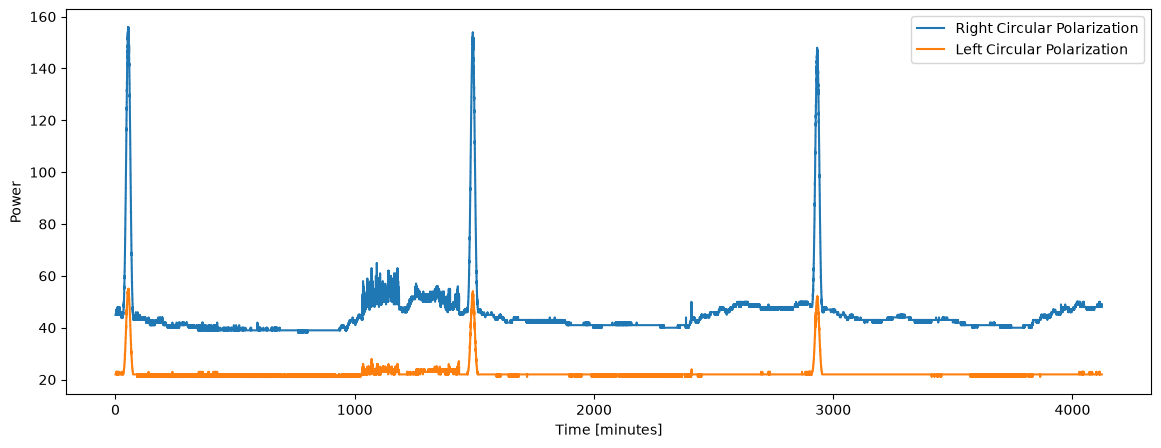

In [134]:
# plot the two polarisations
fig, ax = plt.subplots(
    figsize=(14,5)
)

ax.plot(
    t,
    RT1["RIGHT_POL"],
    label="Right Circular Polarization",
)

ax.plot(
    t,
    RT1["LEFT_POL"],
    label="Left Circular Polarization",
)

ax.set_xlabel("Time [minutes]")
ax.set_ylabel("Power")
ax.legend()

plt.show()

In [135]:
gain_ratio = (
    RT1["RIGHT_POL"].median()
    /
    RT1["LEFT_POL"].median()
)

print(gain_ratio)

1.9545454545454546


In [136]:
RT1["LEFT_GAINCORR"] = (
    RT1["LEFT_POL"]
    * gain_ratio
)

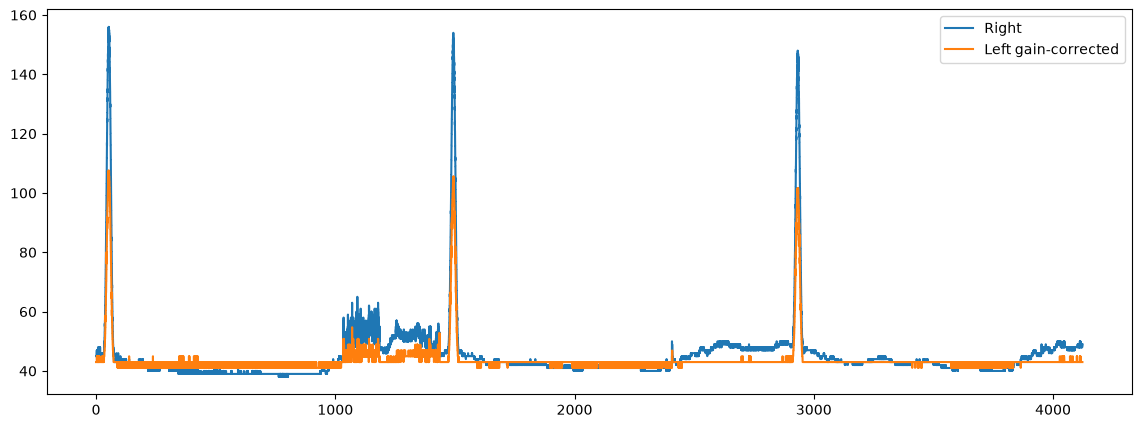

In [137]:
plt.figure(figsize=(14,5))

plt.plot(
    t,
    RT1["RIGHT_POL"],
    label="Right"
)

plt.plot(
    t,
    RT1["LEFT_GAINCORR"],
    label="Left gain-corrected"
)

plt.legend()
plt.show()

In [138]:
R0 = RT1["RIGHT_POL"].quantile(0.1)
L0 = RT1["LEFT_POL"].quantile(0.1)

Rsig = RT1["RIGHT_POL"] - R0
Lsig = RT1["LEFT_POL"] - L0

In [139]:
sun_mask = Rsig > 30

gain = (
    Rsig[sun_mask].sum()
    /
    Lsig[sun_mask].sum()
)

Lcorr = gain * Lsig

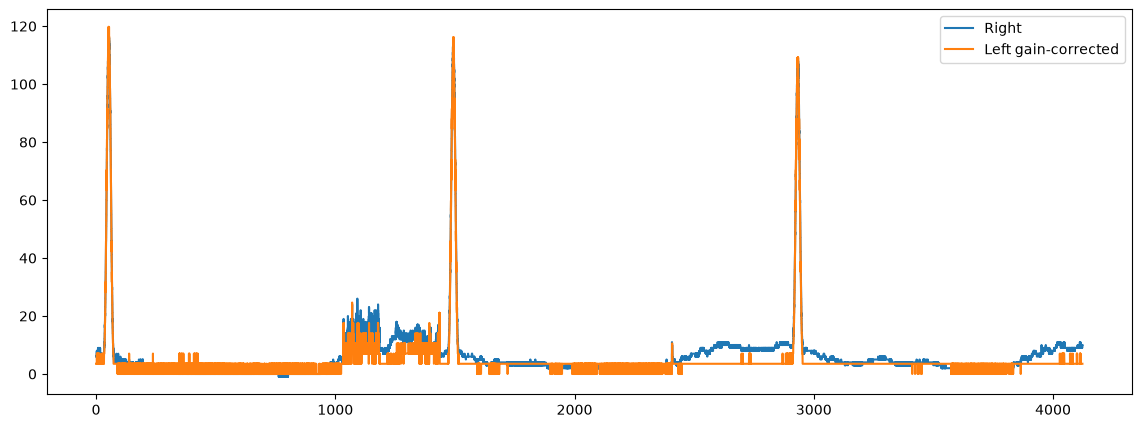

In [140]:
plt.figure(figsize=(14,5))

plt.plot(
    t,
    Rsig,
    label="Right"
)

plt.plot(
    t,
    Lcorr,
    label="Left gain-corrected"
)

plt.legend()
plt.show()

### Polarization Asymmetry
$A = \frac{R-L}{R+L}$

In [141]:
R = Rsig
#L = RT1["LEFT_GAINCORR"]
L = Lcorr

RT1["POL_ASYM"] = (
    R
    -
    L
) / (
    R
    +
    L
    +
    1e-6
)

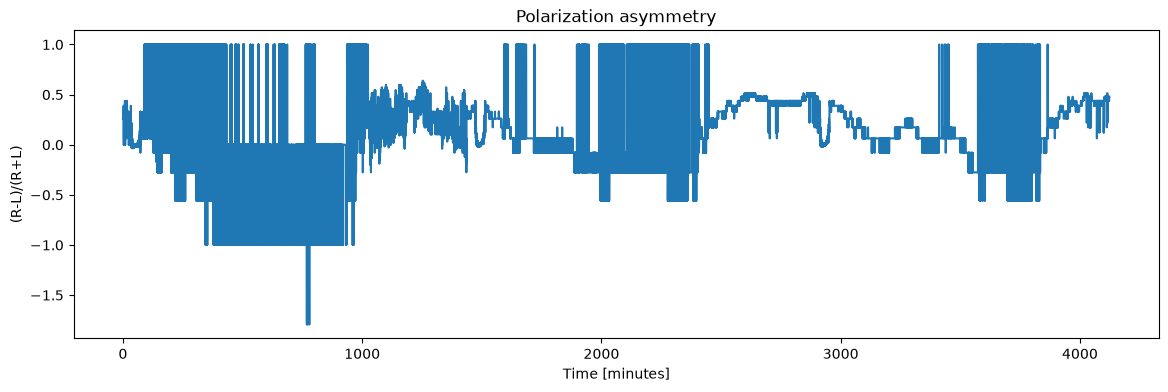

In [142]:
plt.figure(figsize=(14,4))

plt.plot(
    t,
    RT1["POL_ASYM"]
)

plt.xlabel("Time [minutes]")
plt.ylabel("(R-L)/(R+L)")
plt.title("Polarization asymmetry")

plt.show()

### Do the channels always move together?

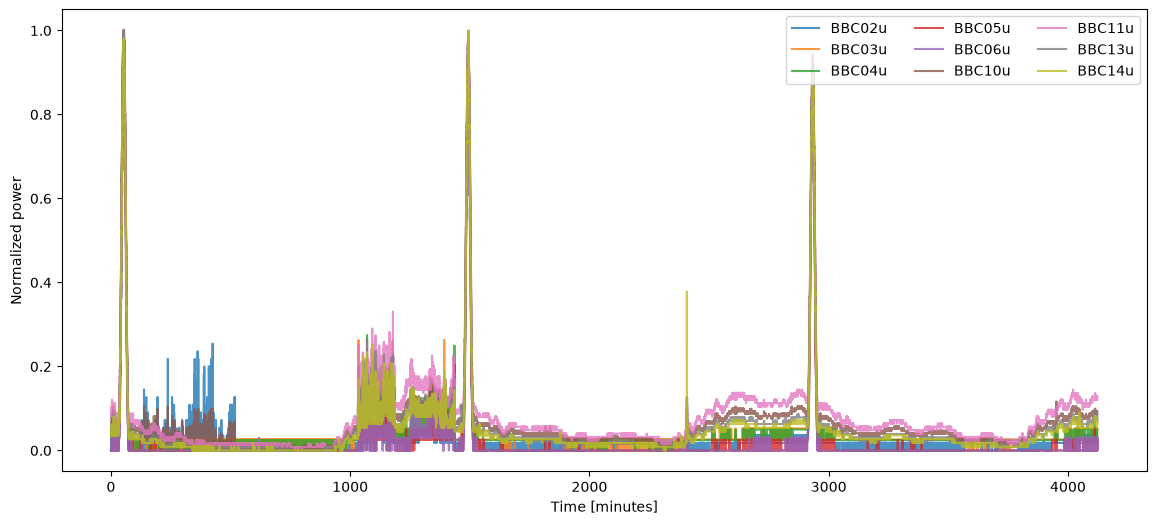

In [143]:
fig, ax = plt.subplots(
    figsize=(14,6)
)

for ch in bbc_channels:
    x = RT1[ch]

    x = (
        x - x.min()
    ) / (
        x.max() - x.min()
    )

    ax.plot(
        t,
        x,
        alpha=0.8,
        label=ch
    )

ax.set_xlabel("Time [minutes]")
ax.set_ylabel("Normalized power")

plt.legend(
    ncol=3
)

plt.show()

### Spectral Features

In [144]:
freqs = np.array([
    1406,
    1414,
    1422,
    1430,
    1438,
    1406,
    1414,
    1430,
    1438
])

In [145]:
def spectral_slope(row):

    y = row[bbc_channels].to_numpy(dtype=float)

    p = np.polyfit(
        freqs,
        y,
        1
    )

    return p[0]


RT1["SPEC_SLOPE"] = RT1.apply(
    spectral_slope,
    axis=1
)

RT1["SPEC_STD"] = (
    RT1[bbc_channels]
    .std(axis=1)
)

### Build ML dataset

In [165]:
features = pd.DataFrame()

features["RIGHT_POL"] = Rsig #RT1["RIGHT_POL"]
features["LEFT_POL"] = Lcorr #RT1["LEFT_POL"]

features["POL_ASYM"] = RT1["POL_ASYM"]

features["SPEC_SLOPE"] = RT1["SPEC_SLOPE"]
features["SPEC_STD"] = RT1["SPEC_STD"]

for ch in bbc_channels:
    features[ch] = RT1[ch]

In [166]:
features = features.dropna()

### Standardization

In [167]:
scaler = StandardScaler()
X = scaler.fit_transform(features)

### PCA = Principal Component Analysis

In [168]:
pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(X)

print(
    pca.explained_variance_ratio_
)

[0.90987042 0.07362649]


### PCA Visualization
The question is: Do strongly polarized measurements occupy a particular region?

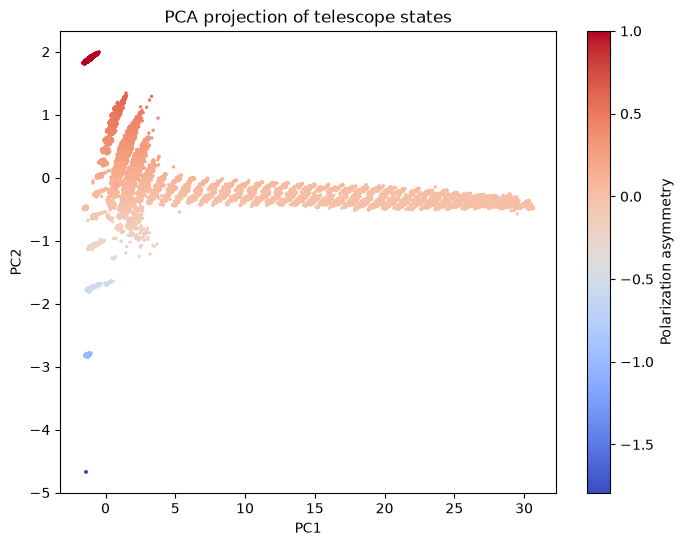

In [169]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    s=2,
    c=features["POL_ASYM"],
    cmap="coolwarm"
)

plt.colorbar(
    label="Polarization asymmetry"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA projection of telescope states"
)

plt.show()

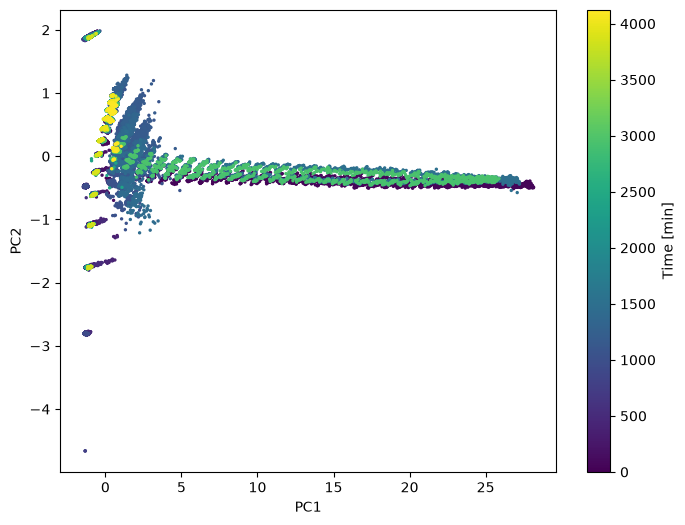

In [151]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=t,
    s=2,
    cmap='viridis'
)

plt.colorbar(label='Time [min]')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

### K-Means Clustering

In [152]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

cluster = kmeans.fit_predict(X)

features["CLUSTER"] = cluster

### PCA with Clusters
The question is: What physical state does each cluster represent?

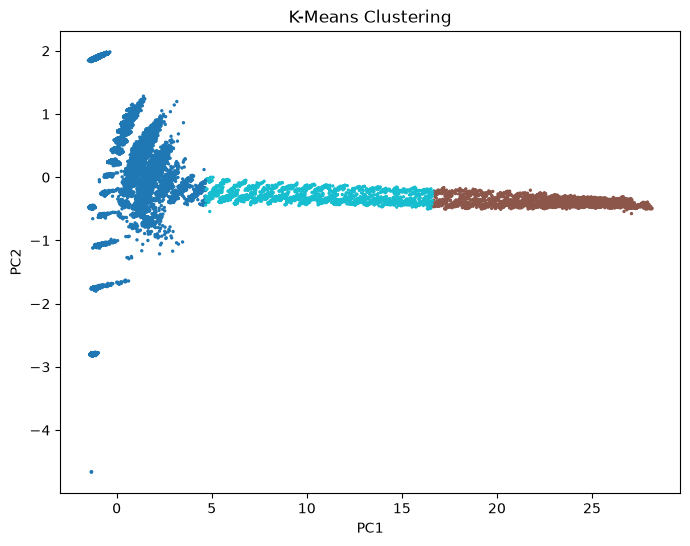

In [153]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=cluster,
    s=2,
    cmap="tab10"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "K-Means Clustering"
)

plt.show()

### Isolation forest

In [154]:
iso = IsolationForest(
    contamination=0.01,
    random_state=42
)

anomaly = iso.fit_predict(X)

features["ANOMALY"] = anomaly

Convenction is:
+1 normal
-1 anomaly

### Anomaly vs time

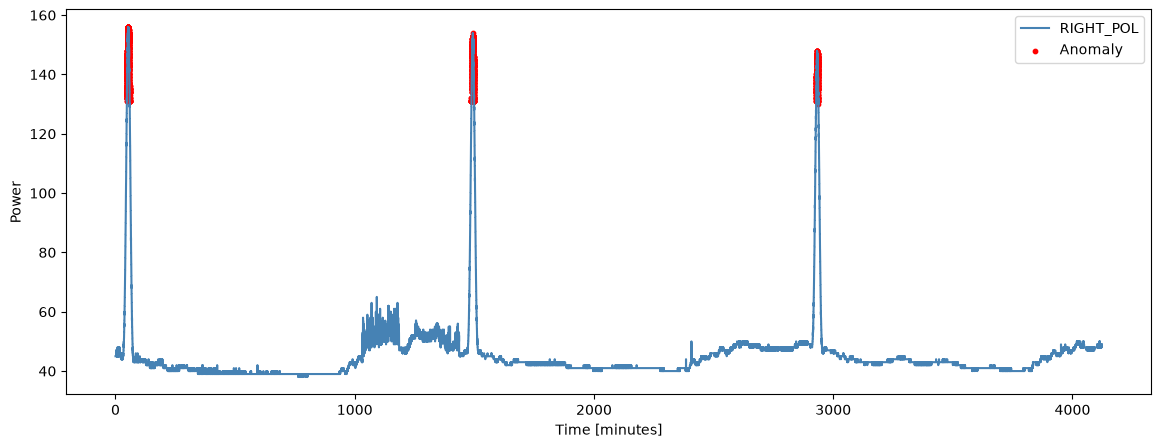

In [155]:
plt.figure(figsize=(14,5))

plt.plot(
    t,
    RT1["RIGHT_POL"],
    color="steelblue",
    label="RIGHT_POL"
)

mask = (
    anomaly == -1
)

plt.scatter(
    t[features.index][mask],
    RT1["RIGHT_POL"].iloc[
        features.index[mask]
    ],
    s=10,
    color="red",
    label="Anomaly"
)

plt.xlabel("Time [minutes]")
plt.ylabel("Power")

plt.legend()

plt.show()

### Anomaly Score and Polarization

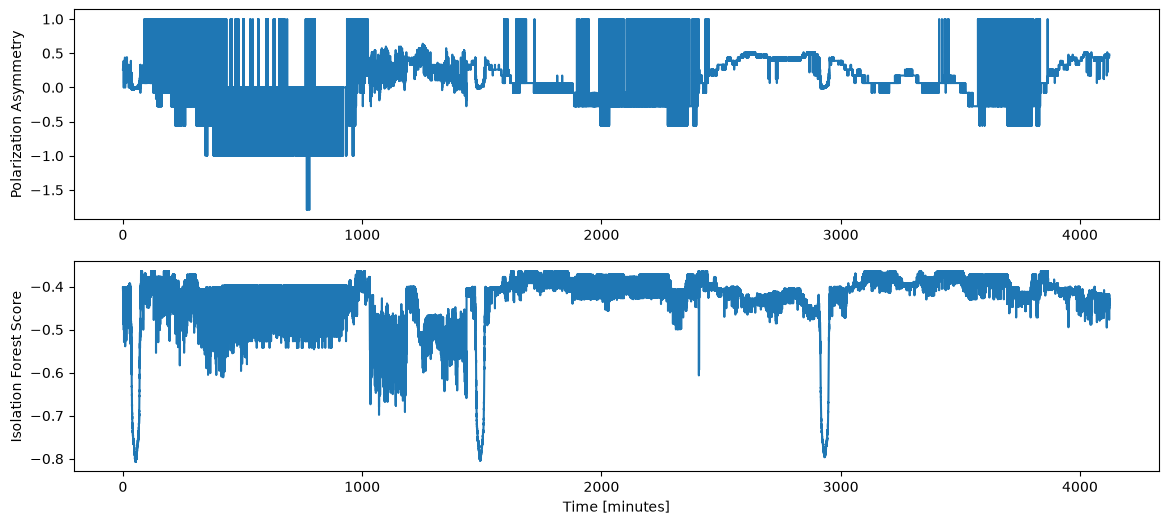

In [156]:
plt.figure(figsize=(14,6))

plt.subplot(211)

plt.plot(
    t,
    RT1["POL_ASYM"]
)

plt.ylabel(
    "Polarization Asymmetry"
)

plt.subplot(212)

score = iso.score_samples(X)

plt.plot(
    t[features.index],
    score
)

plt.ylabel(
    "Isolation Forest Score"
)

plt.xlabel(
    "Time [minutes]"
)

plt.show()

## Conclusions
We used unsupervised machine learning to analyse radio telescope observations.

### Main steps:

Polarization analysis
Spectral feature extraction
PCA dimensionality reduction
K-Means clustering
Isolation Forest anomaly detection


### Questions:

Did the algorithm recover solar transits? <br>
Did it identify unusual observing periods? <br>
Are anomalies associated with strong circular polarization? <br>
Could these anomalies correspond to radio-frequency interference?

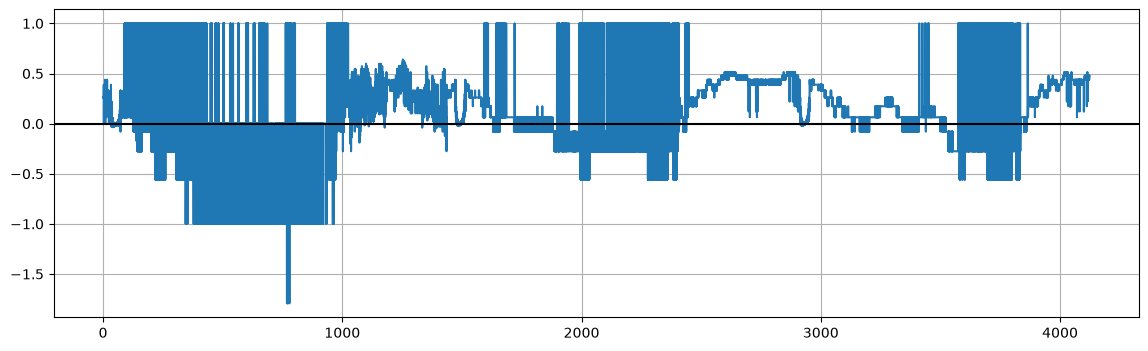

In [157]:
plt.figure(figsize=(14,4))

plt.plot(t, RT1["POL_ASYM"])
plt.axhline(0,color='k')
plt.grid()

In [158]:
plt.figure(figsize=(14,4))

plt.plot(t, RT1["BBC_STD"])
plt.grid()

KeyError: 'BBC_STD'

<Figure size 1400x400 with 0 Axes>

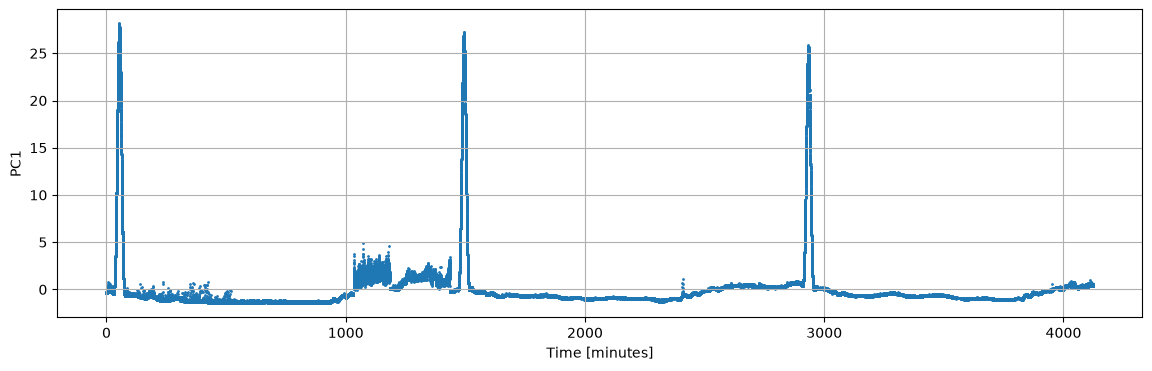

In [159]:
plt.figure(figsize=(14,4))

plt.scatter(
    t,
    X_pca[:,0],
    s=1
)

plt.xlabel("Time [minutes]")
plt.ylabel("PC1")
plt.grid()

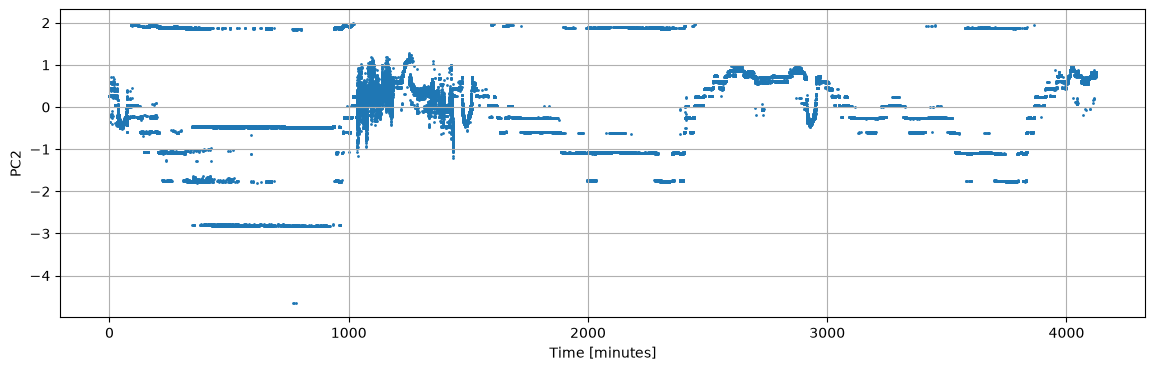

In [160]:
plt.figure(figsize=(14,4))

plt.scatter(
    t,
    X_pca[:,1],
    s=1
)

plt.xlabel("Time [minutes]")
plt.ylabel("PC2")
plt.grid()

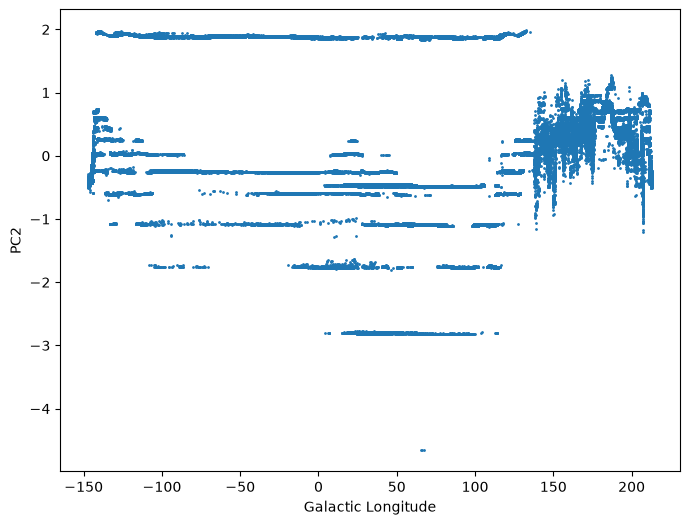

In [161]:
plt.figure(figsize=(8,6))

plt.scatter(
    RT1["Gal_Long"],
    X_pca[:,1],
    s=1
)

plt.xlabel("Galactic Longitude")
plt.ylabel("PC2")
plt.show()

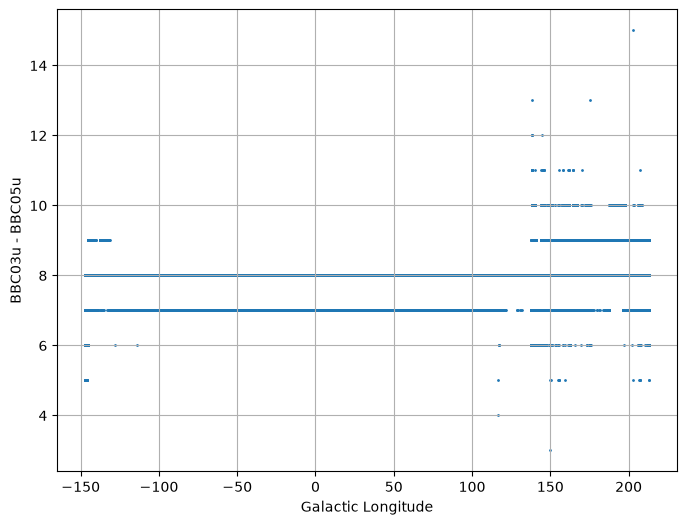

In [162]:
plt.figure(figsize=(8,6))

plt.scatter(
    RT1["Gal_Long"],
    RT1["BBC03u"] - RT1["BBC05u"],
    s=1
)

plt.xlabel("Galactic Longitude")
plt.ylabel("BBC03u - BBC05u")
plt.grid()

In [163]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=features.columns,
    columns=["PC1","PC2"]
)

print(loadings["PC1"].sort_values(key=np.abs, ascending=False))
print()
print(loadings["PC2"].sort_values(key=np.abs, ascending=False))


ValueError: Shape of passed values is (12, 2), indices imply (14, 2)

In [164]:
print(features.shape)
print(X.shape)
print(pca.components_.shape)


(215223, 14)
(215223, 12)
(2, 12)
